Saving flower_sample.png to flower_sample.png


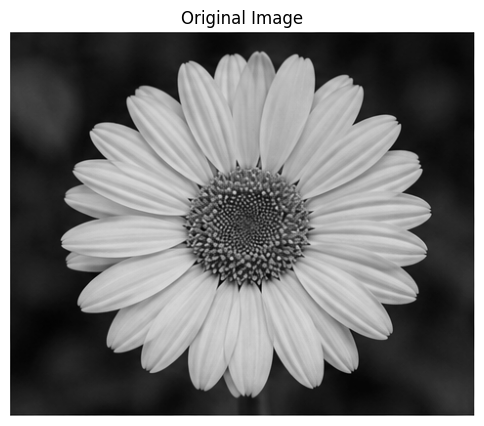

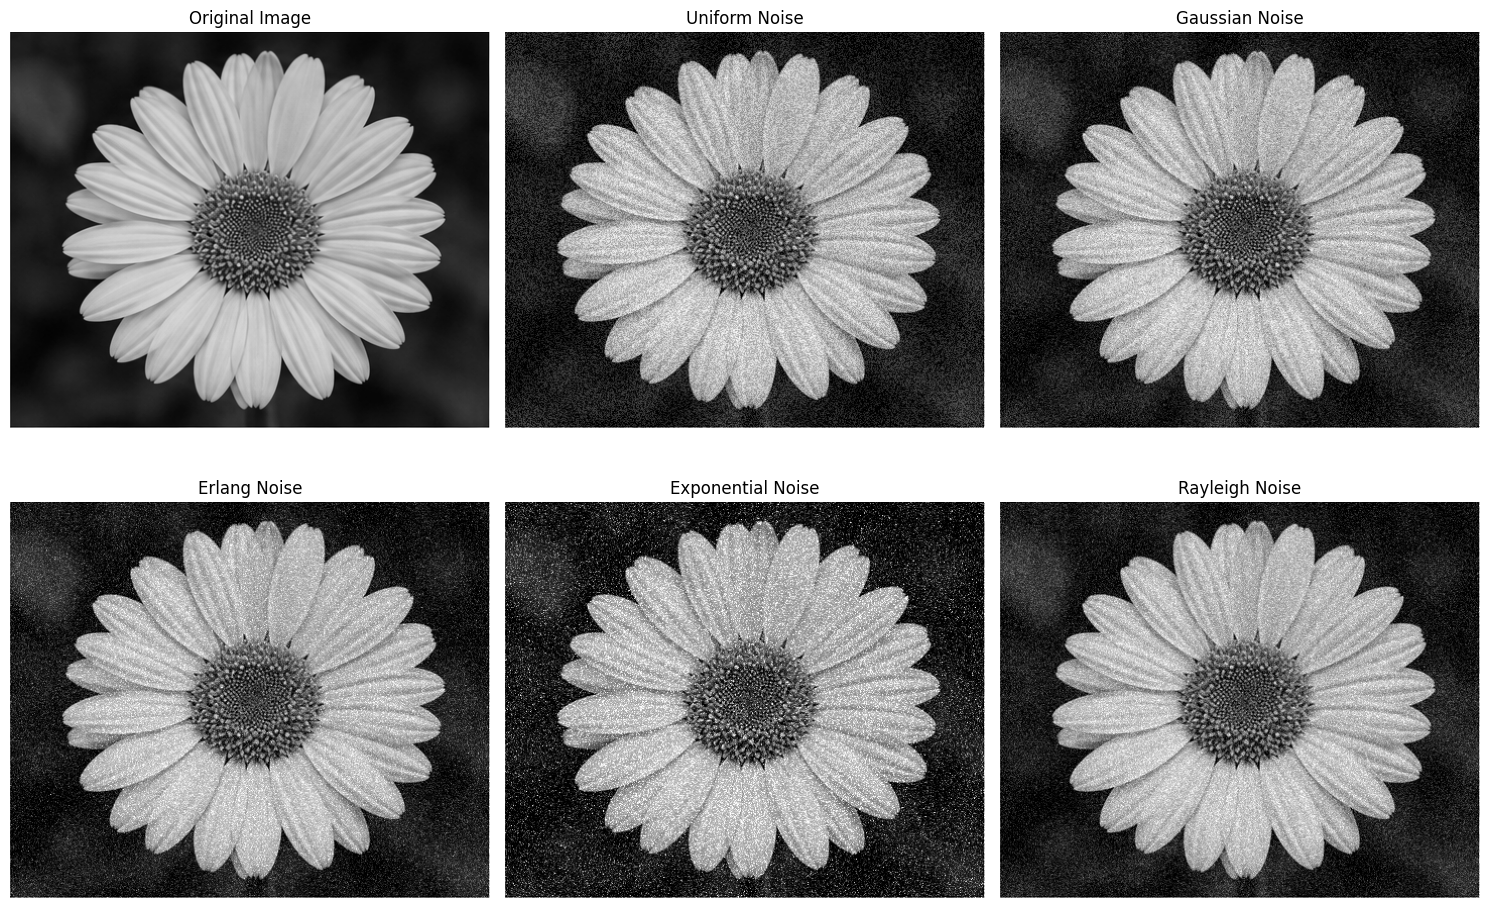

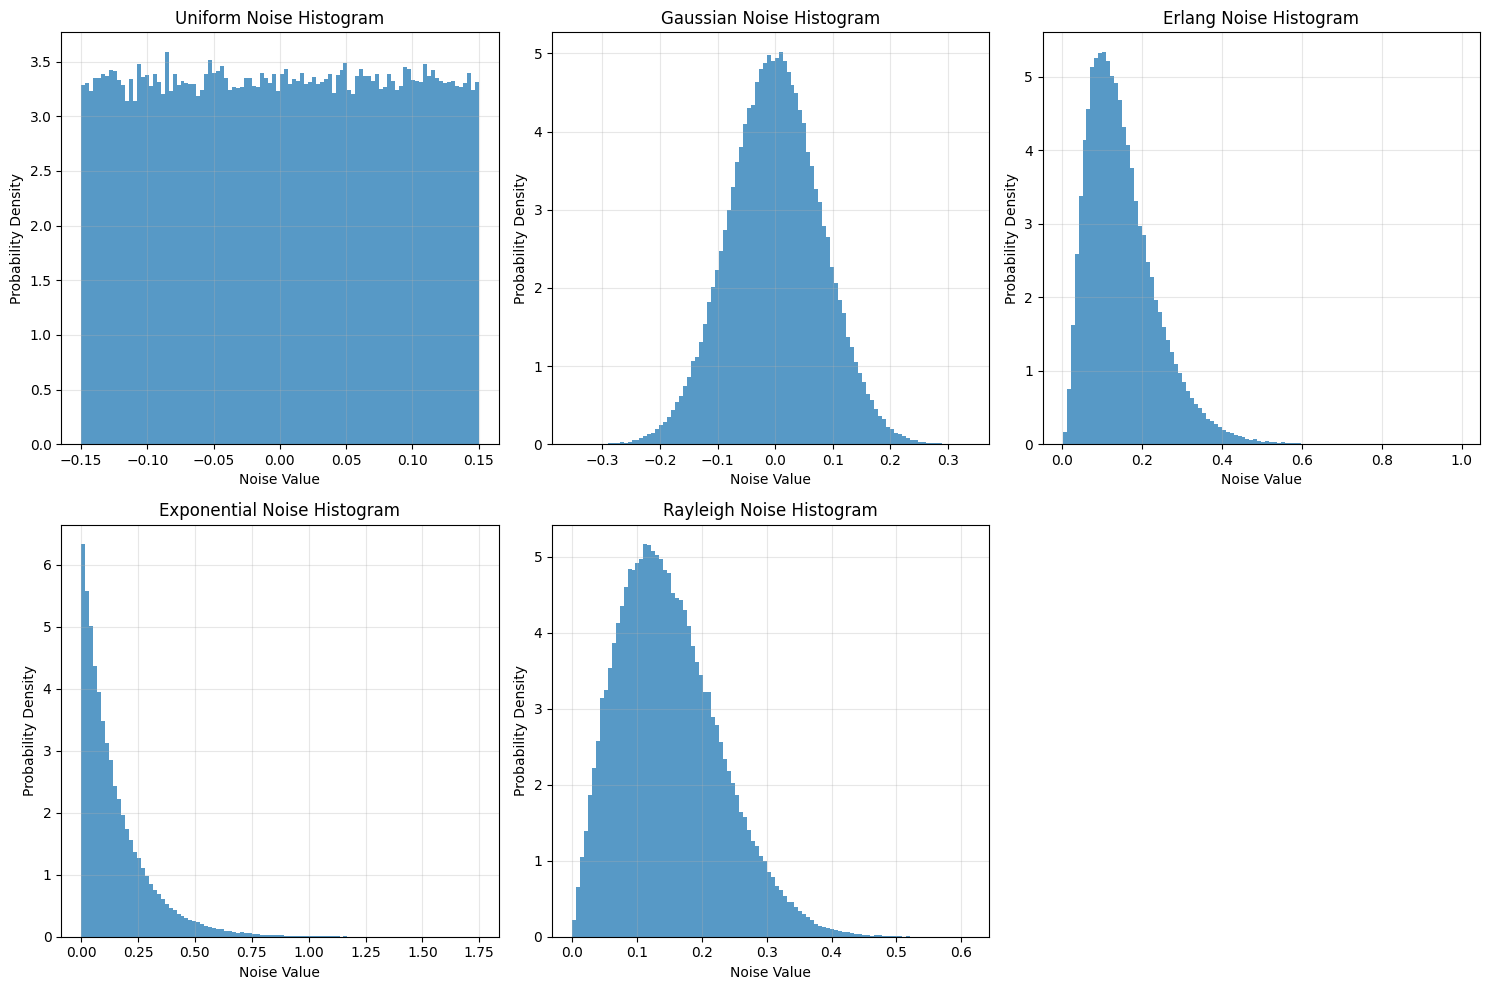

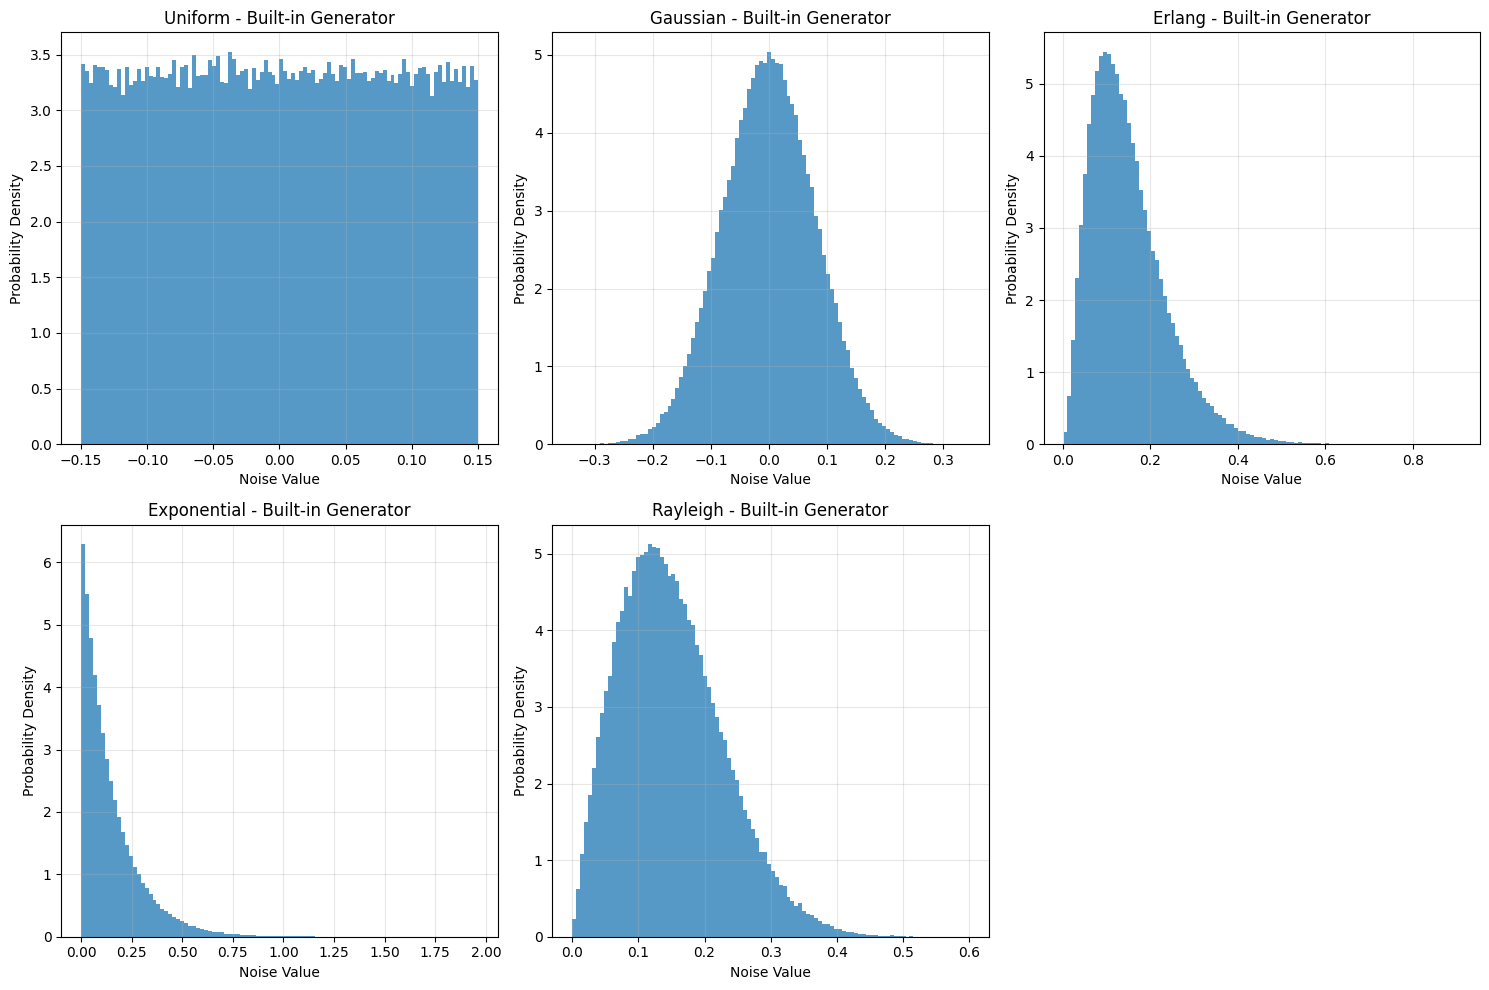

Assignment 8 completed successfully!
Generated five noise distributions.
Displayed noisy images and noise histograms.


In [1]:


import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
image_path = next(iter(uploaded))

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Could not load image. Upload a valid image.")

img = img.astype(np.float64) / 255.0

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title("Original Image")
plt.axis("off")
plt.show()



np.random.seed(42)


a = 0.15
uniform_noise = np.random.uniform(-a, a, img.shape)


mean = 0
sigma = 0.08
gaussian_noise = np.random.normal(mean, sigma, img.shape)


k = 3
theta = 0.05
erlang_raw = np.random.gamma(shape=k, scale=theta, size=img.shape)
erlang_noise = erlang_raw - k * theta


beta = 0.15
exponential_raw = np.random.exponential(scale=beta, size=img.shape)
exponential_noise = exponential_raw - beta


rayleigh_sigma = 0.12
rayleigh_raw = np.random.rayleigh(scale=rayleigh_sigma, size=img.shape)
rayleigh_noise = rayleigh_raw - rayleigh_sigma * np.sqrt(np.pi / 2)



noisy_images = {
    "Uniform Noise": img + uniform_noise,
    "Gaussian Noise": img + gaussian_noise,
    "Erlang Noise": img + erlang_noise,
    "Exponential Noise": img + exponential_noise,
    "Rayleigh Noise": img + rayleigh_noise
}


for name in noisy_images:
    noisy_images[name] = np.clip(noisy_images[name], 0, 1)



plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title("Original Image")
plt.axis("off")

for i, (name, noisy_img) in enumerate(noisy_images.items(), start=2):
    plt.subplot(2, 3, i)
    plt.imshow(noisy_img, cmap="gray", vmin=0, vmax=1)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()



noise_data = {
    "Uniform Noise": uniform_noise,
    "Gaussian Noise": gaussian_noise,
    "Erlang Noise": erlang_raw,
    "Exponential Noise": exponential_raw,
    "Rayleigh Noise": rayleigh_raw
}

plt.figure(figsize=(15, 10))

for i, (name, noise) in enumerate(noise_data.items(), start=1):
    plt.subplot(2, 3, i)

    plt.hist(noise.ravel(), bins=100, density=True, alpha=0.75)

    plt.title(name + " Histogram")
    plt.xlabel("Noise Value")
    plt.ylabel("Probability Density")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


builtin_noise = {
    "Uniform": np.random.uniform(-a, a, img.shape),
    "Gaussian": np.random.normal(mean, sigma, img.shape),
    "Erlang": np.random.gamma(shape=k, scale=theta, size=img.shape),
    "Exponential": np.random.exponential(scale=beta, size=img.shape),
    "Rayleigh": np.random.rayleigh(scale=rayleigh_sigma, size=img.shape)
}

plt.figure(figsize=(15, 10))

for i, (name, noise) in enumerate(builtin_noise.items(), start=1):
    plt.subplot(2, 3, i)
    plt.hist(noise.ravel(), bins=100, density=True, alpha=0.75)
    plt.title(name + " - Built-in Generator")
    plt.xlabel("Noise Value")
    plt.ylabel("Probability Density")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Assignment 8 completed successfully!")
print("Generated five noise distributions.")
print("Displayed noisy images and noise histograms.")